Environment that uses rdkit is enough so far, as long as python version is new enough to handle the type hints from build_dataset.py

# 0. Imports 

In [1]:
%load_ext autoreload
%autoreload 2

In [27]:
import sys
import rdkit

sys.path.append('../')
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import rdMolDraw2D
from src.data_handler import DataHandler
from src.build_dataset import AtomsToBond
from src.build_dataset import BondAtoms

# 1. identify 2 N-H/C-H bonds (randomly?), remove the hydrogens and make them bond = cyclization

experiments with USPTO split number 1

load the data

In [3]:
uspto_list = DataHandler(file_path='../../USPTO_balance/reaction_equilibration/uspto_balance/data/datasets/USPTO_rand/USPTO_rand_1.txt').load_data()
uspto_mol = DataHandler(file_path='../../USPTO_balance/reaction_equilibration/uspto_balance/data/datasets/USPTO_rand/USPTO_rand_1_mol.pkl').load_data()


## 1.1 find the smarts needed to find our matching molecules

In [3]:
# SMARTS for C-H bond
C_H_bond_smarts = '[#6H]'
C_H_bond_smarts_2 = '[CH]'  # only sp3 carbon on chiral center
C_H_bond_smarts_3 = '[c[H]' # invalid
C_H_bond_smarts_4 = '[#6h]' # works on all the carbons linked to an hydrogen on the molecule!!

# SMARTS for N-C bond
N_H_bond_smarts = '[#7H]'   # works 
N_H_bond_smarts_2 = '[#7h]' # works as well and seems to be more general

the substructure is found:  True


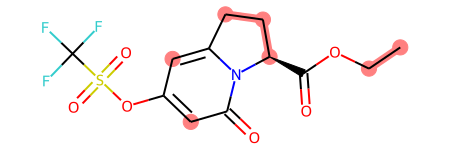

In [73]:
# test C-H bond
print('the substructure is found: ',uspto_mol[0].HasSubstructMatch(Chem.MolFromSmarts(C_H_bond_smarts)))

mol = uspto_mol[0]
patt = Chem.MolFromSmarts(C_H_bond_smarts_4)

hit_ats = list(mol.GetSubstructMatches(patt))[0]
hit_bonds = []
for bond in patt.GetBonds():
   aid1 = hit_ats[bond.GetBeginAtomIdx()]
   aid2 = hit_ats[bond.GetEndAtomIdx()]
   hit_bonds.append(mol.GetBondBetweenAtoms(aid1,aid2).GetIdx())
d = rdMolDraw2D.MolDraw2DSVG(500, 500) # or MolDraw2DCairo to get PNGs
rdMolDraw2D.PrepareAndDrawMolecule(d, mol, highlightAtoms=hit_ats, highlightBonds=hit_bonds)
mol

the substructure is found:  True


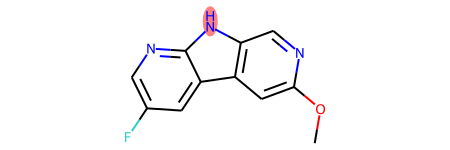

In [75]:
# test N-H bond
print('the substructure is found: ',uspto_mol[1].HasSubstructMatch(Chem.MolFromSmarts(N_H_bond_smarts)))

mol = uspto_mol[1]
patt = Chem.MolFromSmarts(N_H_bond_smarts_2)
hit_ats = list(mol.GetSubstructMatches(patt))[0]
hit_bonds = []
for bond in patt.GetBonds():
   aid1 = hit_ats[bond.GetBeginAtomIdx()]
   aid2 = hit_ats[bond.GetEndAtomIdx()]
   hit_bonds.append(mol.GetBondBetweenAtoms(aid1,aid2).GetIdx())
d = rdMolDraw2D.MolDraw2DSVG(500, 500) # or MolDraw2DCairo to get PNGs
rdMolDraw2D.PrepareAndDrawMolecule(d, mol, highlightAtoms=hit_ats, highlightBonds=hit_bonds)
mol

## 1.2 - Find indices in molecules with AtomstoBond

In [ ]:
# load data
uspto_list = DataHandler(file_path='../../USPTO_balance/reaction_equilibration/uspto_balance/data/datasets/USPTO_rand/USPTO_rand_1.txt').load_data()
uspto_mol = DataHandler(file_path='../../USPTO_balance/reaction_equilibration/uspto_balance/data/datasets/USPTO_rand/USPTO_rand_1_mol.pkl').load_data()

In [4]:
# initialize class for the fictive cyclization reaction
C_H_bond_smarts = '[Ch]' 
N_H_bond_smarts = '[Nh]'

mol = uspto_mol
dict_substructs = {0: C_H_bond_smarts, 1: N_H_bond_smarts} 
dict_conditions = {0:{0:2,1:0}, 1:{0:1, 1:1}}

atomstobond = AtomsToBond(mol, dict_substructs, dict_conditions)

In [5]:
# obtain the list of tuples for each molecule in the dataset
results = atomstobond.get_indices_of_atoms_to_bond_mol_list()

## 1.3 - Create cyclization reactions with BondAtoms

In [20]:
# initialize BondAtoms class with datasets and results from atomstobond
mol_list = uspto_mol
smiles_list = uspto_list
atoms_indices = results
bondatoms = BondAtoms(mol_list=mol_list, smiles_list=smiles_list, atoms_indices=atoms_indices)

In [23]:
# create the dataframe with the information about the cyclization reaction on the 1506 first molecules of our USPTO split
df = bondatoms.create_and_save_cyclization_df(filename='df_cyclization_1506_first_uspto_mol.csv')

build dataframe structure..
dataframe structure ready.
starting cyclic mols obtention..
cyclic mols obtained, converting to smiles..
starting mapped cyclic mols obtention..
mapped cyclic mols obtained, converting to smiles..
dataframe fully ready
Adding reactions to dataframe
preparing reactions..
preparing mapped reactions..
finished reactions
saving dataframe..


In [61]:
el = 953

/var/folders/sp/fbh0lt9x1bl_8wsyrwk01hmr0000gn/T/ipykernel_15156/1205673133.py:18: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, SVG


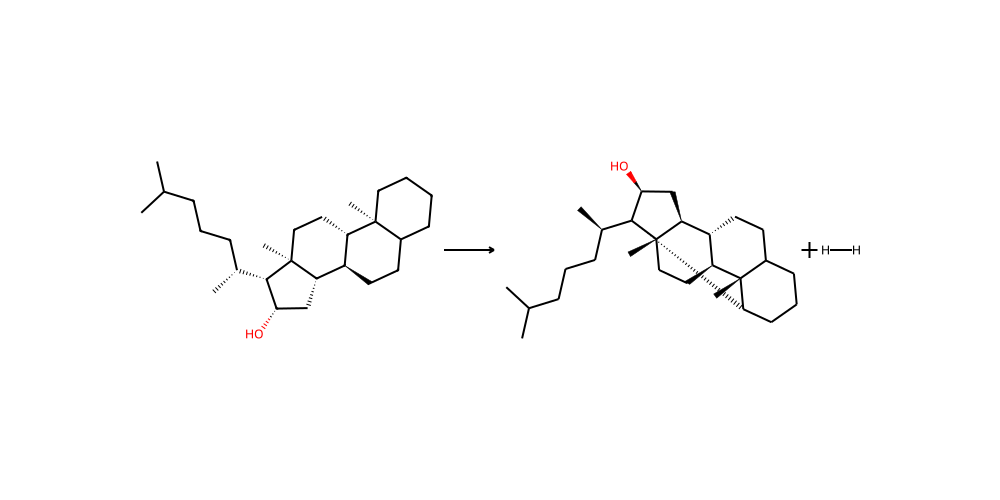

In [62]:
reaction_smarts = df['reaction'].iloc[el]

#display(AllChem.ReactionFromSmarts(reaction_smarts, useSmiles=True))

# Create the reaction object
reaction = AllChem.ReactionFromSmarts(reaction_smarts, useSmiles=True)

# Configure the drawer with a larger size
drawer = rdMolDraw2D.MolDraw2DSVG(1000, 500)  # Width x Height in pixels
#drawer.drawOptions().addAtomIndices = True  # Optional: Show atom indices
#drawer.drawOptions().bondLineWidth = 3  # Optional: Increase bond thickness

# Draw the reaction
drawer.DrawReaction(reaction)
drawer.FinishDrawing()

# Display the SVG in Jupyter Notebook
from IPython.core.display import display, SVG
svg = drawer.GetDrawingText()
display(SVG(svg))

/var/folders/sp/fbh0lt9x1bl_8wsyrwk01hmr0000gn/T/ipykernel_15156/3561065522.py:18: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, SVG


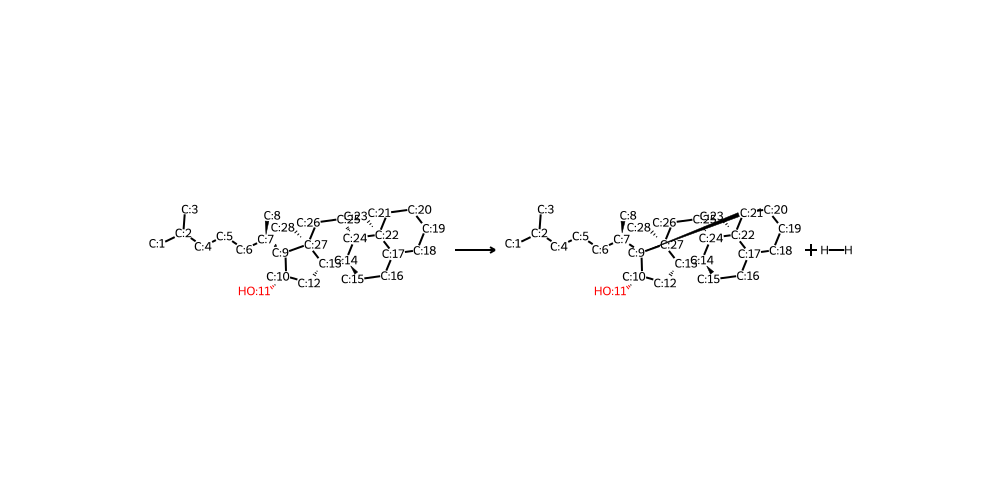

In [63]:
reaction_smarts = df['mapped_reaction'].iloc[el]

#display(AllChem.ReactionFromSmarts(reaction_smarts, useSmiles=True))

# Create the reaction object
reaction = AllChem.ReactionFromSmarts(reaction_smarts, useSmiles=True)

# Configure the drawer with a larger size
drawer = rdMolDraw2D.MolDraw2DSVG(1000, 500)  # Width x Height in pixels
#drawer.drawOptions().addAtomIndices = True  # Optional: Show atom indices
#drawer.drawOptions().bondLineWidth = 3  # Optional: Increase bond thickness

# Draw the reaction
drawer.DrawReaction(reaction)
drawer.FinishDrawing()

# Display the SVG in Jupyter Notebook
from IPython.core.display import display, SVG
svg = drawer.GetDrawingText()
display(SVG(svg))

# 2. Rearrangement types

## 2.1 - Random bond A-B breaking and reconnecting

In [ ]:
# does not need a specific substructure to be matched on the molecule

## 2.2 - Reverse metathesis (DB)

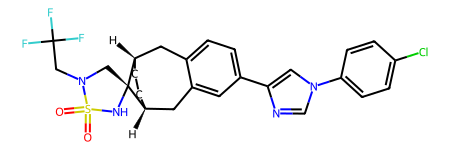

In [77]:
#R1R2-C=C-R1R2 + R3R4-C=C-R3R4 -> R1R2-C=C-R3R4 + R3R4-C=C-R1R2 
# (there is probably something to pay attention to regarding stereochemistry)
# consider at least 1 DB from aliphatic carbon
# consider max 1 double bond in a cycle
# do NOT consider aromatic rings
uspto_mol[11]

In [ ]:
# here, the required substructures are two C=C bonds
substructure = '#6=#6'

## 2.3 - Beckmann rearrangement